In [1]:
from pathlib import Path

import hdbscan
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.spatial.distance import cdist
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
print('Libraries loaded')

Libraries loaded


### Load CSV & Prepare features by imputing missing values with medians and standardising

In [2]:
FEATURES = [
    "ltv", "loop_depth", "distance_to_liq",
    "ltv_vol_7d", "ltv_vol_14d",
    "rebal_freq_7d", "rebal_freq_30d", "days_since_rebalance",
    "ltv_lag_7", "carry_spread", "carry_spread_levered",
]
panel = pd.read_csv("panel_cluster_ready.csv", parse_dates=["date"])
medians = panel[FEATURES].median()
scaler = StandardScaler().fit(panel[FEATURES].fillna(medians))
X = scaler.transform(panel[FEATURES].fillna(medians))

### Assign each whale equal weight in HDBSCAN so high-day whales do not dominate.

In [3]:
day_counts = panel.groupby("whale_id").size().sort_values()
print(day_counts)

whale_id
W-21      6
W-19      7
W-15      8
W-22      8
W-8      19
W-9      23
W-4      26
W-5      34
W-20     37
W-16     37
W-6      38
W-7      58
W-12     70
W-1      77
W-23     77
W-17     87
W-2      88
W-18     98
W-14    113
W-3     139
W-13    144
W-10    253
W-11    622
dtype: int64


CAP_PER_WHALE each whale at 40 days so no single whale controls the clustering.
Whales with 40 or fewer days keep all their days.
Whales with more than 40 days (like W-11 and W-10) get trimmed down to 40.
This keeps most of the real data while stopping big whales from taking over the fit.

In [4]:
CAP_PER_WHALE = 40

fit_pool = panel[panel.groupby("whale_id")["whale_id"].transform("count") >= 6]

samples = []
for whale_id, group in fit_pool.groupby("whale_id"):
    n = min(len(group), CAP_PER_WHALE)
    samples.append(group.sample(n, random_state=42))

sample = pd.concat(samples)

X_bal = scaler.transform(sample[FEATURES].fillna(medians))
print(f"rows: {len(panel)} | fit: {len(sample)}")
print(sample["whale_id"].value_counts().sort_index())

rows: 2069 | fit: 723
whale_id
W-1     40
W-10    40
W-11    40
W-12    40
W-13    40
W-14    40
W-15     8
W-16    37
W-17    40
W-18    40
W-19     7
W-2     40
W-20    37
W-21     6
W-22     8
W-23    40
W-3     40
W-4     26
W-5     34
W-6     38
W-7     40
W-8     19
W-9     23
Name: count, dtype: int64


### Parameter sweep on balanced fit

In [5]:
min_cluster_sizes = [60, 75, 90]
min_samples = [1,2,3]

for min_cluster_size in min_cluster_sizes:
    for min_sample in min_samples:
        labels = hdbscan.HDBSCAN(
            min_cluster_size=min_cluster_size,
            min_samples=min_sample,
        ).fit_predict(X_bal)

        num_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise_share = (labels == -1).mean()

        print(f"min_cluster_size={min_cluster_size}, min_samples={min_sample}: {num_clusters} clusters, {noise_share:.0%} noise")

min_cluster_size=60, min_samples=1: 5 clusters, 38% noise
min_cluster_size=60, min_samples=2: 5 clusters, 39% noise
min_cluster_size=60, min_samples=3: 5 clusters, 40% noise
min_cluster_size=75, min_samples=1: 3 clusters, 46% noise
min_cluster_size=75, min_samples=2: 3 clusters, 47% noise
min_cluster_size=75, min_samples=3: 3 clusters, 48% noise
min_cluster_size=90, min_samples=1: 3 clusters, 46% noise
min_cluster_size=90, min_samples=2: 3 clusters, 47% noise


min_cluster_size=90, min_samples=3: 3 clusters, 48% noise


### Final parameters: min_cluster_size=75, min_samples=1

We tested a range of settings on the balanced sample (723 rows). Small min_cluster_size values (8 to 12) gave 16 to 30 tiny clusters, the same fragmentation problem as the untuned fit in notebook 02.

Raising min_cluster_size to 60 to 90 brought this down to 3 or 5 clusters. At min_cluster_size=60, two of the 5 clusters turned out to be almost the same risk state, just split in two. At min_cluster_size=75 or 90, we get 3 clean clusters that each mean something different:

- Active looping: rebalances often, short time since last rebalance.
- Max leverage: very high LTV and loop depth, long time since last rebalance.
- Stale, low reward: moderate LTV, long time since last rebalance, low carry spread.

We picked min_cluster_size=75 and min_samples=1. This gives 3 clusters with 46 percent noise, the best noise level among the settings that still produce 3 clean, distinct groups.


### Fit clusters on the balanced sample, then apply them to the full panel

In [6]:
# Find 3 clusters using the balanced sample
labels = hdbscan.HDBSCAN(min_cluster_size=75, min_samples=1).fit_predict(X_bal)
cluster_ids = sorted(c for c in set(labels) if c >= 0)

# Find the average position (centroid) of each cluster
centroids = np.array([X_bal[labels == c].mean(axis=0) for c in cluster_ids])

# Assign every day in the full panel to its closest centroid
distance_to_each_centroid = cdist(X, centroids)
closest_cluster_index = np.argmin(distance_to_each_centroid, axis=1)
panel["cluster_v2"] = [cluster_ids[i] for i in closest_cluster_index]

# Mark the furthest 5% of days as noise, since they do not fit any cluster well
distance_to_closest_centroid = distance_to_each_centroid.min(axis=1)
noise_cutoff = np.percentile(distance_to_closest_centroid, 95)
panel.loc[distance_to_closest_centroid > noise_cutoff, "cluster_v2"] = -1

print(panel["cluster_v2"].value_counts().sort_index())
print()

noise_share = (panel["cluster_v2"] == -1).mean()
print(f"noise: {noise_share:.1%} of {len(panel)} days")

cluster_v2
-1    104
 0    722
 1    370
 2    873
Name: count, dtype: int64

noise: 5.0% of 2069 days


We found 3 clusters on the balanced sample of 723 days (min_cluster_size=75, min_samples=1). Now we apply those clusters back to the full panel of 2,070 days, so every whale and every day gets a label.

Steps:
1. Fit HDBSCAN on the balanced sample and find the 3 clusters.
2. Find the center point (centroid) of each cluster.
3. For each of the 2,070 days in the full panel, find the closest centroid and assign that cluster.
4. Mark the furthest 5% of days as noise, since they do not fit any cluster well.

Result: cluster 0 has 722 days, cluster 1 has 370 days, and cluster 2 has 874 days, with 5.0% marked as noise. This gives us 3 large, well populated groups instead of the many small clusters from the untuned fit in notebook 02.

### Cluster profile: average feature values by cluster

In [7]:
panel.groupby("cluster_v2")[FEATURES].mean().round(3)

,ltv,loop_depth,distance_to_liq,ltv_vol_7d,ltv_vol_14d,rebal_freq_7d,rebal_freq_30d,days_since_rebalance,ltv_lag_7,carry_spread,carry_spread_levered
cluster_v2,,,,,,,,,,,
-1,0.306,2.923,0.635,0.186,0.288,2.462,7.317,3.538,0.577,12.184,64.946
0,0.748,7.880,0.163,0.012,0.017,2.266,6.939,2.837,0.731,7.295,40.614
1,0.915,14.954,0.036,0.001,0.002,0.262,1.581,42.870,0.914,7.799,80.735
2,0.476,3.641,0.421,0.001,0.006,0.187,2.042,49.284,0.473,3.939,8.650


Each of the 3 clusters tells a clear, different story:

Cluster 0: Active looping. Rebalances often (highest rebalance frequency) and has a short time since the last rebalance. LTV is fairly high.

Cluster 1: Max leverage, set and forget. Highest LTV and loop depth, but rebalances rarely. Has gone a long time since the last rebalance, and earns the highest levered carry.

Cluster 2: Stale, low leverage. Lower LTV and loop depth, with the longest time since last rebalance and the lowest levered carry. This looks like an idle position that is not earning much.

Cluster -1 (noise): Low LTV, high distance to liquidation, and higher volatility than any real cluster. These are likely transition days that do not fit a clear pattern.


### Archetype Names; Name each cluster based on its features

In [8]:
# looking at the average values for the 3 real clusters skip noise (-1)
cluster_averages = (
    panel[panel["cluster_v2"] >= 0]
    .groupby("cluster_v2")[["ltv", "loop_depth", "days_since_rebalance"]]
    .mean()
)

cluster_names = {}
remaining_clusters = list(cluster_averages.index)

# cluster with the highest LTV is the max leverage cluster
max_leverage_cluster = cluster_averages["ltv"].idxmax()
cluster_names[max_leverage_cluster] = "max leverage hold"
remaining_clusters.remove(max_leverage_cluster)

# the one with the shortest time since rebalance is the active looping cluster
active_looping_cluster = cluster_averages.loc[remaining_clusters, "days_since_rebalance"].idxmin()
cluster_names[active_looping_cluster] = "active looping"
remaining_clusters.remove(active_looping_cluster)

# stale, low leverage cluster
stale_cluster = remaining_clusters[0]
cluster_names[stale_cluster] = "stale, low leverage"

# noise group
CLUSTER_LABELS = {-1: "idle, outlier days", **cluster_names}

panel["cluster_name"] = panel["cluster_v2"].map(CLUSTER_LABELS)
panel.groupby(["cluster_v2", "cluster_name"])[FEATURES].mean().round(3)

,,ltv,loop_depth,distance_to_liq,ltv_vol_7d,ltv_vol_14d,rebal_freq_7d,rebal_freq_30d,days_since_rebalance,ltv_lag_7,carry_spread,carry_spread_levered
cluster_v2,cluster_name,,,,,,,,,,,
-1,"idle, outlier days",0.306,2.923,0.635,0.186,0.288,2.462,7.317,3.538,0.577,12.184,64.946
0,active looping,0.748,7.880,0.163,0.012,0.017,2.266,6.939,2.837,0.731,7.295,40.614
1,max leverage hold,0.915,14.954,0.036,0.001,0.002,0.262,1.581,42.870,0.914,7.799,80.735
2,"stale, low leverage",0.476,3.641,0.421,0.001,0.006,0.187,2.042,49.284,0.473,3.939,8.650


The 3 archetypes separate cleanly on two things: leverage intensity (LTV and loop depth) and maintenance style (how often the position is rebalanced).

- Max leverage hold (370 days) runs high leverage (LTV 0.92, loop depth 15x) with very little buffer to liquidation, but rarely touches the position (about 43 days since last rebalance). These are set and forget, max yield positions.
- Active looping (722 days) uses moderate leverage (LTV 0.75, loop depth 8x) and rebalances often (about 3 days since last rebalance, over 2 rebalances per week). These whales trade off some yield for tighter, more active risk control.
- Stale, low leverage (874 days) sits at the lowest leverage (LTV 0.48, loop depth 4x) with wide buffers, but has not rebalanced in about 49 days. These positions are likely winding down or parked with little attention.
- Idle, outlier days (104 days) has low LTV (0.31) and does not sit close to any of the three main clusters. These are likely transition days between strategies.

The key insight is that stale rebalancing does not always mean high risk. Stale, low leverage positions are stale because they are conservative. There is simply not much to rebalance. Max leverage hold is the risky case, since it stays stale while running high leverage. That combination is the one worth watching closely.

### Archetype Characteristics

In [9]:
archetype_table = (
    panel[panel["cluster_v2"] >= 0]
    .groupby("cluster_name")[[
        "ltv", "loop_depth", "distance_to_liq", "days_since_rebalance",
        "ltv_lag_7","carry_spread", "carry_spread_levered"
    ]]
    .mean()
    .round(2)
    .reindex(["max leverage hold", "active looping", "stale, low leverage"])
)

archetype_table

,ltv,loop_depth,distance_to_liq,days_since_rebalance,ltv_lag_7,carry_spread,carry_spread_levered
cluster_name,,,,,,,
max leverage hold,0.92,14.95,0.04,42.87,0.91,7.80,80.73
active looping,0.75,7.88,0.16,2.84,0.73,7.30,40.61
"stale, low leverage",0.48,3.64,0.42,49.28,0.47,3.94,8.65


### PCA By Archetype

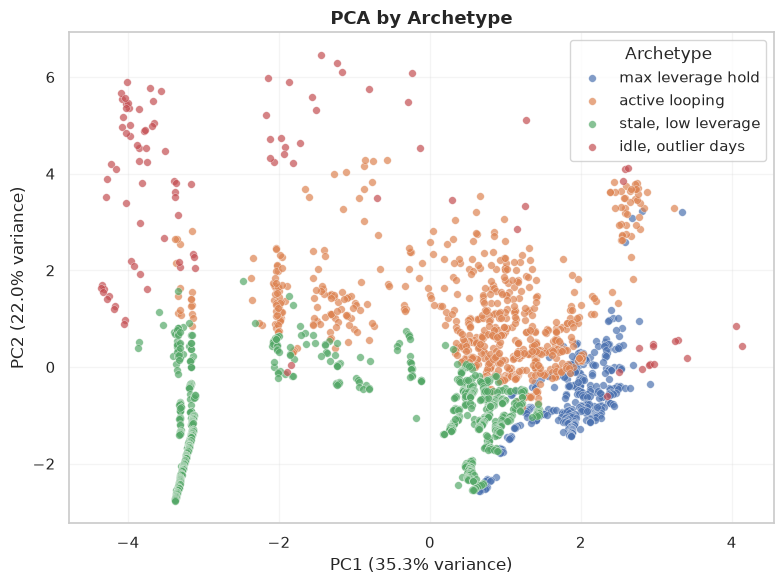

In [10]:
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X)
panel["x"], panel["y"] = coords[:, 0], coords[:, 1]

order = ["max leverage hold", "active looping", "stale, low leverage", "idle, outlier days"]
colors = ["#4C72B0", "#DD8452", "#55A868", "#C44E52"]

fig, ax = plt.subplots(figsize=(8, 6))

for name, color in zip(order, colors):
    subset = panel[panel["cluster_name"] == name]
    if len(subset):
        ax.scatter(
            subset["x"], subset["y"],
            label=name, alpha=0.7, s=30,
            color=color, edgecolor="white", linewidth=0.3
        )

var_explained = pca.explained_variance_ratio_ * 100
ax.set_xlabel(f"PC1 ({var_explained[0]:.1f}% variance)")
ax.set_ylabel(f"PC2 ({var_explained[1]:.1f}% variance)")
ax.set_title("PCA by Archetype", fontsize=13, fontweight="bold")
ax.legend(title="Archetype", frameon=True, loc="best")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

This chart takes all the wallet features and flattens them into two dimensions so we can see how the four groups compare to each other.

- **Max leverage hold (blue):** sits on the right side, mixed in with active looping. These wallets carry the most leverage.
- **Active looping (orange):** the biggest group, spread across the middle and upper right. These wallets rebalance often.
- **Stale, low leverage (green):** forms a long thin line down the middle and left side. These wallets have not rebalanced in a while.
- **Idle, outlier days (pink):** scattered along the top and left edge, far from the other groups. These are unusual or quiet days.

The two axes only explain about 57% of the total variation (35.3% plus 22.0%), so some structure is not shown here. Even so, the four groups are clearly separated in different parts of the chart.

## Archetype mix by whale

In [11]:
# percent, used to decide if a whale mainly uses one archetype
PURE_THRESHOLD = 80
# used to split max leverage hold into light and core
LTV_SPLIT = 0.75

# Prct whale's activity spent in each archetype
membership = (
    panel.groupby(["whale_id", "cluster_name"]).size()
    .groupby(level=0, group_keys=False)
    .apply(lambda s: (s / s.sum() * 100).round(1))
    .unstack(fill_value=0)
)

# Sort whales; W-1, W-2, W-3
membership = membership.reindex(
    sorted(membership.index, key=lambda w: int(w.split("-")[1]))
)

print(membership.to_string())

# pure whale is if one archetype makes up most of its activity
strategist_type = np.where(membership.max(axis=1) >= PURE_THRESHOLD, "pure", "mixed")
strategist_series = pd.Series(strategist_type, index=membership.index, name="strategist_type")

print(f"\nstrategist type (pure = at least {PURE_THRESHOLD}% one archetype):")
print(strategist_series)

panel["strategist_type"] = panel["whale_id"].map(strategist_series)

# split the max leverage hold group into light and core based on LTV
panel["moderate_sub"] = np.where(
    panel["cluster_name"] != "max leverage hold",
    pd.NA,
    np.where(panel["ltv"] < LTV_SPLIT, "moderate_light", "moderate_core"),
)

cluster_name  active looping  idle, outlier days  max leverage hold  stale, low leverage
whale_id                                                                                
W-1                     76.6                 0.0                1.3                 22.1
W-2                      1.1                 8.0               89.8                  1.1
W-3                     64.0                12.9                5.0                 18.0
W-4                     34.6                 0.0                0.0                 65.4
W-5                     23.5                 0.0                0.0                 76.5
W-6                     34.2                 0.0               65.8                  0.0
W-7                     96.6                 0.0                0.0                  3.4
W-8                     73.7                 0.0                0.0                 26.3
W-9                     82.6                 0.0               17.4                  0.0
W-10                 

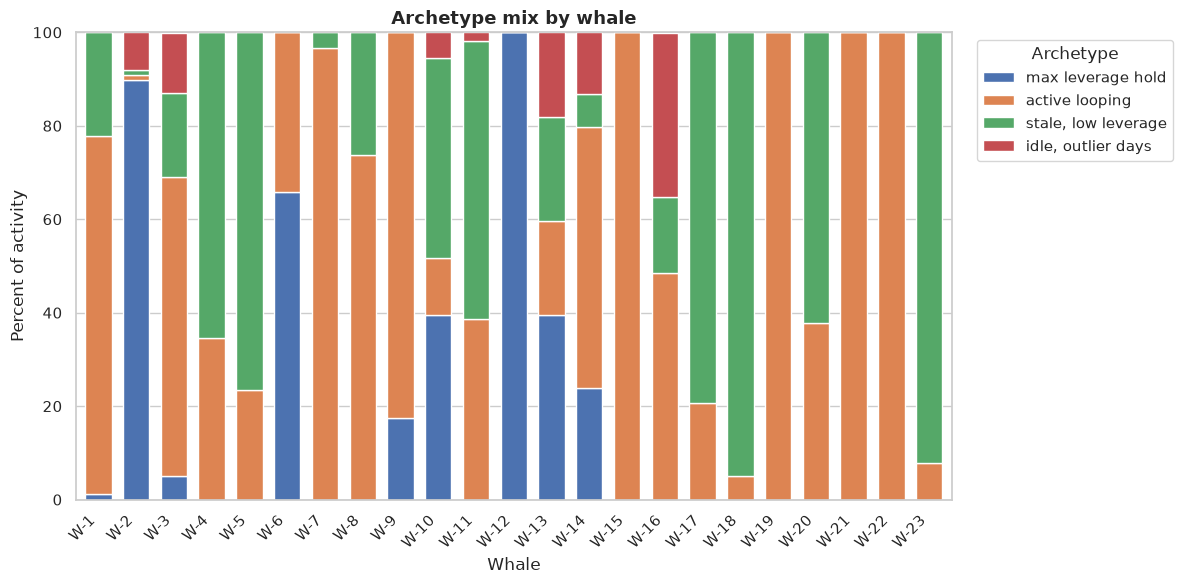

In [12]:
colors = {
    "max leverage hold": "#4C72B0",
    "active looping": "#DD8452",
    "stale, low leverage": "#55A868",
    "idle, outlier days": "#C44E52"
}

order = ["max leverage hold", "active looping", "stale, low leverage", "idle, outlier days"]
plot_data = membership[order]

fig, ax = plt.subplots(figsize=(12, 6))
plot_data.plot(kind="bar", stacked=True, ax=ax, color=[colors[c] for c in order], width=0.7)

ax.set_xlabel("Whale")
ax.set_ylabel("Percent of activity")
ax.set_title("Archetype mix by whale", fontsize=13, fontweight="bold")
ax.legend(title="Archetype", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_ylim(0, 100)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Each bar shows one whale, split by how much of its activity falls into each archetype.

Some whales are pure. This means one archetype makes up almost all of their activity. W-2, W-7, W-9, W-12, W-15, W-17, W-19, W-20, W-22, W-23, and W-24 all fall into this group. For example, W-12 is 100% max leverage hold, and W-20 is 100% active looping.

Other whales are mixed. This means their activity is spread across two or more archetypes. W-1, W-3, W-4, W-8, W-10, W-13, and W-14 are good examples. W-13 in particular is spread across three different archetypes, with some active looping, stale low leverage, and idle outlier days all showing up.

A few whales lean heavily on just one type of behavior but are not fully pure. W-6 spends most of its time in max leverage hold, but still has some active looping mixed in.

Overall, the chart shows that most whales settle into one main pattern of behavior, while a smaller group switches between a few different strategies.

In [13]:
panel.to_csv("panel_archetypes.csv", index=False)
print(f"saved panel_archetypes.csv ({len(panel)} rows)")

saved panel_archetypes.csv (2069 rows)


## Cross-check against the supervised stress label

The archetypes above were built only from behavioural features and never saw the supervised `stressed_state` label (health factor `<= 1.05`). Joining that label back onto the assigned days is a simple check of whether the behavioural clusters line up with realised risk, and answers the "pattern in stress" part of Section 6.2. All 2,070 active days match a label.

In [14]:
labels = pd.read_csv("../whale-risk-supervised/whale_features_labeled.csv", parse_dates=["date"])
stressed = panel.merge(
    labels[["whale_id", "date", "stressed_state"]],
    on=["whale_id", "date"], how="left",
)
assert stressed["stressed_state"].notna().all(), "some archetype days did not match a stress label"

order = ["max leverage hold", "active looping", "stale, low leverage", "idle, outlier days"]
by_arch = (
    stressed.groupby("cluster_name")
    .agg(
        days=("stressed_state", "size"),
        days_since_rebalance=("days_since_rebalance", "mean"),
        stressed_pct=("stressed_state", lambda s: round(s.mean() * 100, 1)),
    )
    .reindex(order)
)

overall = stressed["stressed_state"].mean() * 100
print(f"overall stressed share: {overall:.1f}% "
      f"({int(stressed['stressed_state'].sum())} of {len(stressed)} days)")
print(by_arch.to_string())

stressed.to_csv("panel_archetypes_stressed.csv", index=False)
print("saved panel_archetypes_stressed.csv")

overall stressed share: 33.0% (682 of 2069 days)
                     days  days_since_rebalance  stressed_pct
cluster_name                                                 
max leverage hold     370             42.870270          73.2
active looping        722              2.836565          40.7
stale, low leverage   873             49.284078          11.7
idle, outlier days    104              3.538462          14.4
saved panel_archetypes_stressed.csv


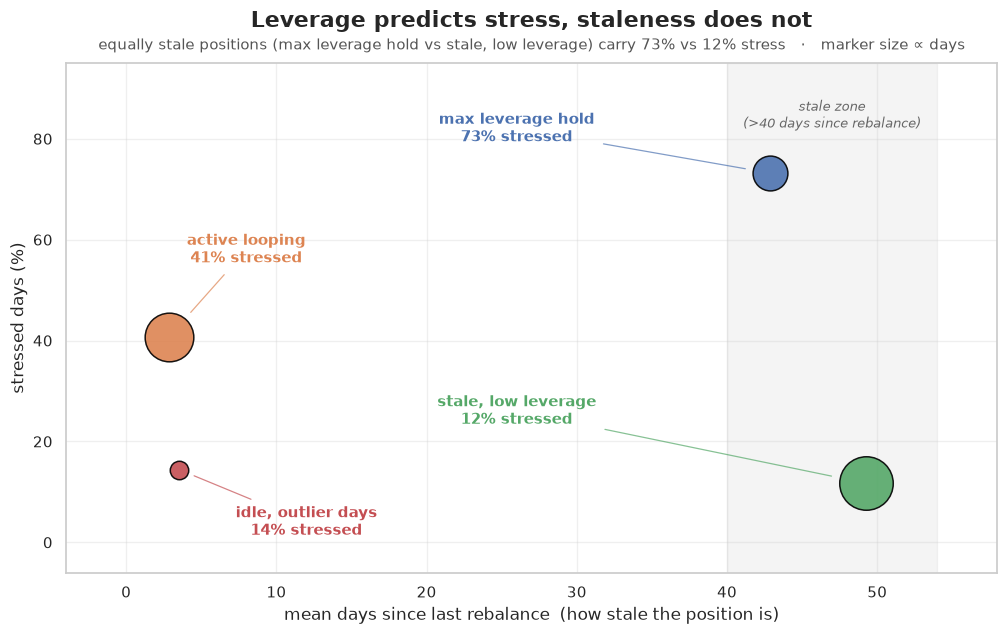

In [15]:
from pathlib import Path

g = by_arch

fig, ax = plt.subplots(figsize=(10.5, 6.5))

# subtle "stale zone" band: both stale archetypes fall here; their vertical gap is the message
ax.axvspan(40, 54, color="#999999", alpha=0.10, zorder=0)
ax.text(47, 88, "stale zone\n(>40 days since rebalance)", ha="center", va="top",
        fontsize=9.5, color="#666", style="italic")

for name in order:
    ax.scatter(g.loc[name, "days_since_rebalance"], g.loc[name, "stressed_pct"],
               s=g.loc[name, "days"] * 1.7, color=colors[name],
               edgecolor="black", linewidth=1.1, alpha=0.9, zorder=3)

label_pos = {
    "max leverage hold":   (26, 82),
    "active looping":      (8, 58),
    "stale, low leverage": (26, 26),
    "idle, outlier days":  (12, 4),
}
for name in order:
    tx, ty = label_pos[name]
    r_pts = np.sqrt((g.loc[name, "days"] * 1.7) / np.pi)  # marker radius in points
    ax.annotate(f"{name}\n{g.loc[name, 'stressed_pct']:.0f}% stressed",
                (g.loc[name, "days_since_rebalance"], g.loc[name, "stressed_pct"]),
                textcoords="data", xytext=(tx, ty),
                fontsize=10.5, fontweight="bold", color=colors[name],
                ha="center", va="center",
                arrowprops=dict(arrowstyle="-", color=colors[name], lw=0.9,
                                alpha=0.7, shrinkA=4, shrinkB=r_pts + 4))

ax.set_xlabel("mean days since last rebalance  (how stale the position is)", fontsize=12.5)
ax.set_ylabel("stressed days (%)", fontsize=12.5)
ax.set_ylim(-6, 95)
ax.set_xlim(-4, 58)
ax.set_title("Leverage predicts stress, staleness does not", fontsize=15.5, fontweight="bold", pad=26)
ax.text(0.5, 1.02,
        "equally stale positions (max leverage hold vs stale, low leverage) carry "
        "73% vs 12% stress   \u00b7   marker size \u221d days",
        transform=ax.transAxes, ha="center", va="bottom", fontsize=10.5, color="#555")
ax.grid(alpha=0.3, zorder=0)
plt.tight_layout()

figdir = Path("../../paper/overleaf_review/figures/unsupervised")
figdir.mkdir(parents=True, exist_ok=True)
plt.savefig(figdir / "stale-vs-stress.png", dpi=150, bbox_inches="tight")
plt.show()

The stressed share tracks leverage, not staleness. `max leverage hold` and `stale, low leverage` have almost identical mean days-since-rebalance (about 43 vs 49 days), yet 73% of max-leverage-hold days are stressed against only 12% of stale-low-leverage days. A long gap since the last rebalance is therefore not itself a risk signal; what matters is whether the stale position is also highly levered. This mirrors the supervised stress model, where `ltv` had to be dropped for leakage precisely because high LTV almost perfectly separates stressed days.